Dataset Shape: (50000, 2)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB

Missing Values:
review       0
sentiment    0
dtype: int64

Duplicate Reviews:
418

Dataset Shape After Removing Duplicates: (49582, 2)
Duplicates After Removing: 0

Sentiment Distribution:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


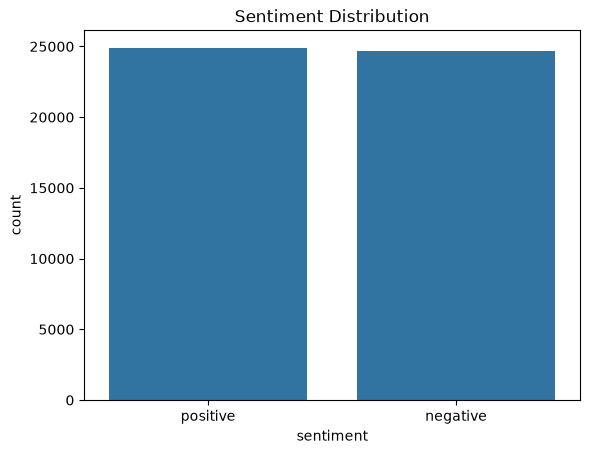


Original Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru

Cleaned Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me. The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this

Encoded Labels:
  sentiment  label
0  positive      1
1  positive      1
2  positive      1
3  negative      0
4  positive      1

Label Distribution:
label
1    24884
0    24698
Name: count, dtype: int64

Training Samples: 34707
Validation Samples: 7437
Testing Samples: 7438

Original Review:
I work in a library and expected to like this movie when it came ou

In [2]:
from Data_exploration import (
    X_train_pad,
    X_val_pad,
    X_test_pad,
    y_train,
    y_val,
    y_test,
    MAX_WORDS,
    MAX_LEN
)

In [3]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

In [4]:
model_lstm = Sequential([
    Input(shape=(MAX_LEN,)),

    Embedding(
        input_dim=MAX_WORDS,
        output_dim=128
    ),

    LSTM(
        units=64,
        activation="tanh"
    ),

    Dropout(0.3),

    Dense(
        units=1,
        activation="sigmoid"
    )
])


In [5]:
model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,609,473 (9.95 MB)

 Trainable params: 2,609,473 (9.95 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model_lstm.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [7]:
early_stop_lstm = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

In [8]:
history_lstm = model_lstm.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5,
    batch_size=64,
    callbacks=[early_stop_lstm],
    verbose=1
)

Epoch 1/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 75s 134ms/step - accuracy: 0.5079 - loss: 0.6952 - val_accuracy: 0.5009 - val_loss: 0.6931
Epoch 2/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 65s 119ms/step - accuracy: 0.5263 - loss: 0.6852 - val_accuracy: 0.5127 - val_loss: 0.6917
Epoch 3/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 68s 125ms/step - accuracy: 0.5413 - loss: 0.6733 - val_accuracy: 0.5415 - val_loss: 0.6773
Epoch 4/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 68s 126ms/step - accuracy: 0.5757 - loss: 0.6320 - val_accuracy: 0.5625 - val_loss: 0.6591
Epoch 5/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 69s 126ms/step - accuracy: 0.7851 - loss: 0.4535 - val_accuracy: 0.8537 - val_loss: 0.3500


In [9]:
test_loss, test_accuracy = model_lstm.evaluate(
    X_test_pad,
    y_test
)

print("\nLSTM Test Loss:", test_loss)
print("LSTM Test Accuracy:", test_accuracy)

233/233 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.8516 - loss: 0.3593

LSTM Test Loss: 0.35932281613349915
LSTM Test Accuracy: 0.8515729904174805


In [10]:
y_pred_prob = model_lstm.predict(X_test_pad)

y_pred_lstm = (y_pred_prob >= 0.5).astype(int).flatten()

233/233 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step


In [11]:
print("\nLSTM Classification Report:")

print(
    classification_report(
        y_test,
        y_pred_lstm,
        target_names=["Negative", "Positive"]
    )
)


LSTM Classification Report:
              precision    recall  f1-score   support

    Negative       0.92      0.77      0.84      3705
    Positive       0.80      0.93      0.86      3733

    accuracy                           0.85      7438
   macro avg       0.86      0.85      0.85      7438
weighted avg       0.86      0.85      0.85      7438



In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

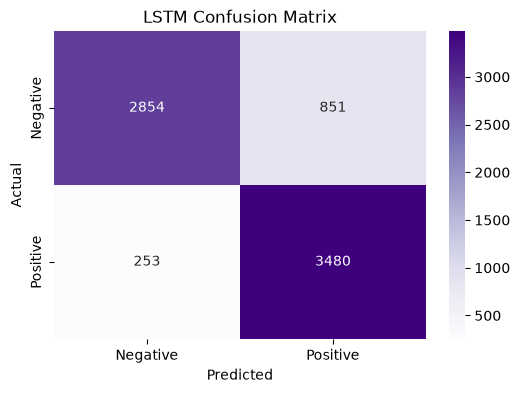

In [13]:

cm_lstm = confusion_matrix(
    y_test,
    y_pred_lstm
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LSTM Confusion Matrix")

plt.show()



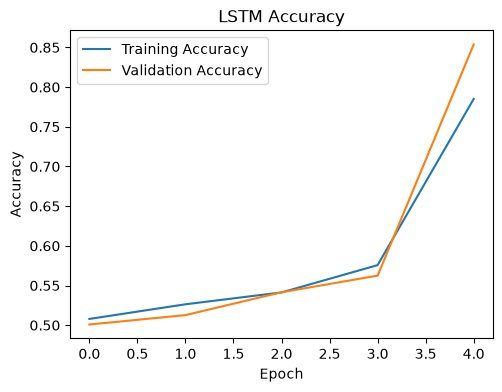

In [14]:

plt.figure(figsize=(12, 4))


plt.subplot(1, 2, 1)

plt.plot(
    history_lstm.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_lstm.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("LSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()



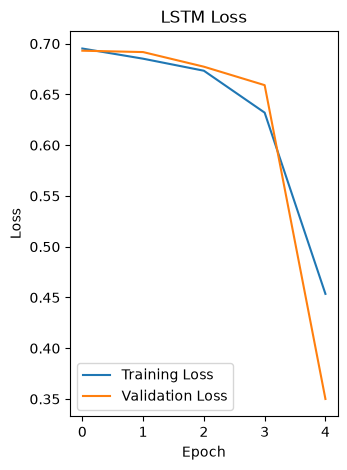

In [15]:
plt.subplot(1, 2, 2)

plt.plot(
    history_lstm.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [16]:

import os

os.makedirs("models", exist_ok=True)

model_lstm.save("models/lstm_model.keras")

print("\nLSTM Model Saved Successfully!")



LSTM Model Saved Successfully!
